# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [109]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [110]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users =pd.read_csv('/datasets/users_latam.csv') 
usage = pd.read_csv('/datasets/usage.csv')

In [190]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [154]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [155]:
usage.head()

,id,user_id,type,date,duration,length,is_text,is_call,min_llamada
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN,0,1,0.09
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0,1,0,0.00
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0,1,0,0.00
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN,0,1,1.53
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN,0,1,4.84


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [156]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", plans.shape)
print("usage", plans.shape)

plans (2, 8)
users (2, 8)
usage (2, 8)


In [157]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [158]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   float64       
 4   city        3435 non-null   object        
 5   reg_date    3960 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 250.1+ KB


In [159]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   id           40000 non-null  int64         
 1   user_id      40000 non-null  int64         
 2   type         40000 non-null  object        
 3   date         39950 non-null  datetime64[ns]
 4   duration     17924 non-null  float64       
 5   length       22104 non-null  float64       
 6   is_text      40000 non-null  int64         
 7   is_call      40000 non-null  int64         
 8   min_llamada  40000 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(4), object(1)
memory usage: 2.7+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [160]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           565
reg_date        40
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.14125
reg_date      0.01000
plan          0.00000
churn_date    0.88350
dtype: float64


In [161]:
print(usage.isna().sum())
print(usage.isna().mean())

id                 0
user_id            0
type               0
date              50
duration       22076
length         17896
is_text            0
is_call            0
min_llamada        0
dtype: int64
id             0.00000
user_id        0.00000
type           0.00000
date           0.00125
duration       0.55190
length         0.44740
is_text        0.00000
is_call        0.00000
min_llamada    0.00000
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  ciudad, y duracion son las que tienen mas valores nulos 
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [162]:

print(users['user_id'].describe())
print(users['age'].describe())


count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64
count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [163]:
print(usage['id'].describe())
print(usage['user_id'].describe())

count    40000.00000
mean     20000.50000
std      11547.14972
min          1.00000
25%      10000.75000
50%      20000.50000
75%      30000.25000
max      40000.00000
Name: id, dtype: float64
count    40000.000000
mean     12002.405975
std       1157.279564
min      10000.000000
25%      10996.000000
50%      12013.000000
75%      13005.000000
max      13999.000000
Name: user_id, dtype: float64


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [164]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())


          city    plan
count     3435    4000
unique       6       2
top     Bogotá  Basico
freq       808    2595


In [165]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  city y age, age tenia vcalores imposibles y city tenia datos faltantes
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [166]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [167]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [168]:
# Revisar los años presentes en `reg_date` de users

(users['reg_date'].dt.year == 2026).sum()


0

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
fechas regulares 2022, 2026, 2023, 2024 , lo raro aqui es que no deberia de haber mas a;nos que 2024 
2026 es un error;;; 40 resultados de 2026 

In [169]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()
usage['date'].dt.year.isna().sum()

50

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas. 2024 y una fecha improbable que es nan;;; 
50 resultados nan 

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- si aparecen 
- ¿Qué harías con ellas? los dejaria ya que son muy pocos 
- age en users: valores -999 (anómalos).
city en users: 469 valores nulos.
reg_date en users: 40 filas con año 2026 inválido.
date en usage: 50 valores nulos
los dejare marcados por el momento 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [170]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999] ['age'].median()
users['age'] = users['age'].replace (-999, age_mediana)
# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [171]:
# Reemplazar ? por NA en city
users['city'] = users ['city'].replace ('?', np.nan )



# Verificar cambios
users['city'].isna().sum()

565

In [172]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date']= pd.NaT
# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [173]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [174]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [175]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)
usage['min_llamada'] = usage['duration'].where(usage['type'] == 'call', 0)


# Agrupar información por usuario
tabla = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
   cant_llamadas=('is_call', 'sum'),
    cant_minutos_llamada=('min_llamada', 'sum')
).reset_index()

# observar resultado
tabla.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [176]:
tabla.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [177]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(tabla,users, on ='user_id', how='inner')
user_profile.head(5)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [178]:
tabla[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].agg(
    ['mean', 'median', 'min', 'max', 'std'])



,cant_mensajes,cant_llamadas,cant_minutos_llamada
mean,5.524381,4.478120,22.836934
median,5.000000,4.000000,19.740000
min,0.000000,0.000000,0.000000
max,17.000000,15.000000,155.690000
std,2.358416,2.144238,16.590213


In [179]:
# Distribución porcentual del tipo de plan
(users['plan'].value_counts(normalize=True, dropna=False) * 100).round(2)


Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

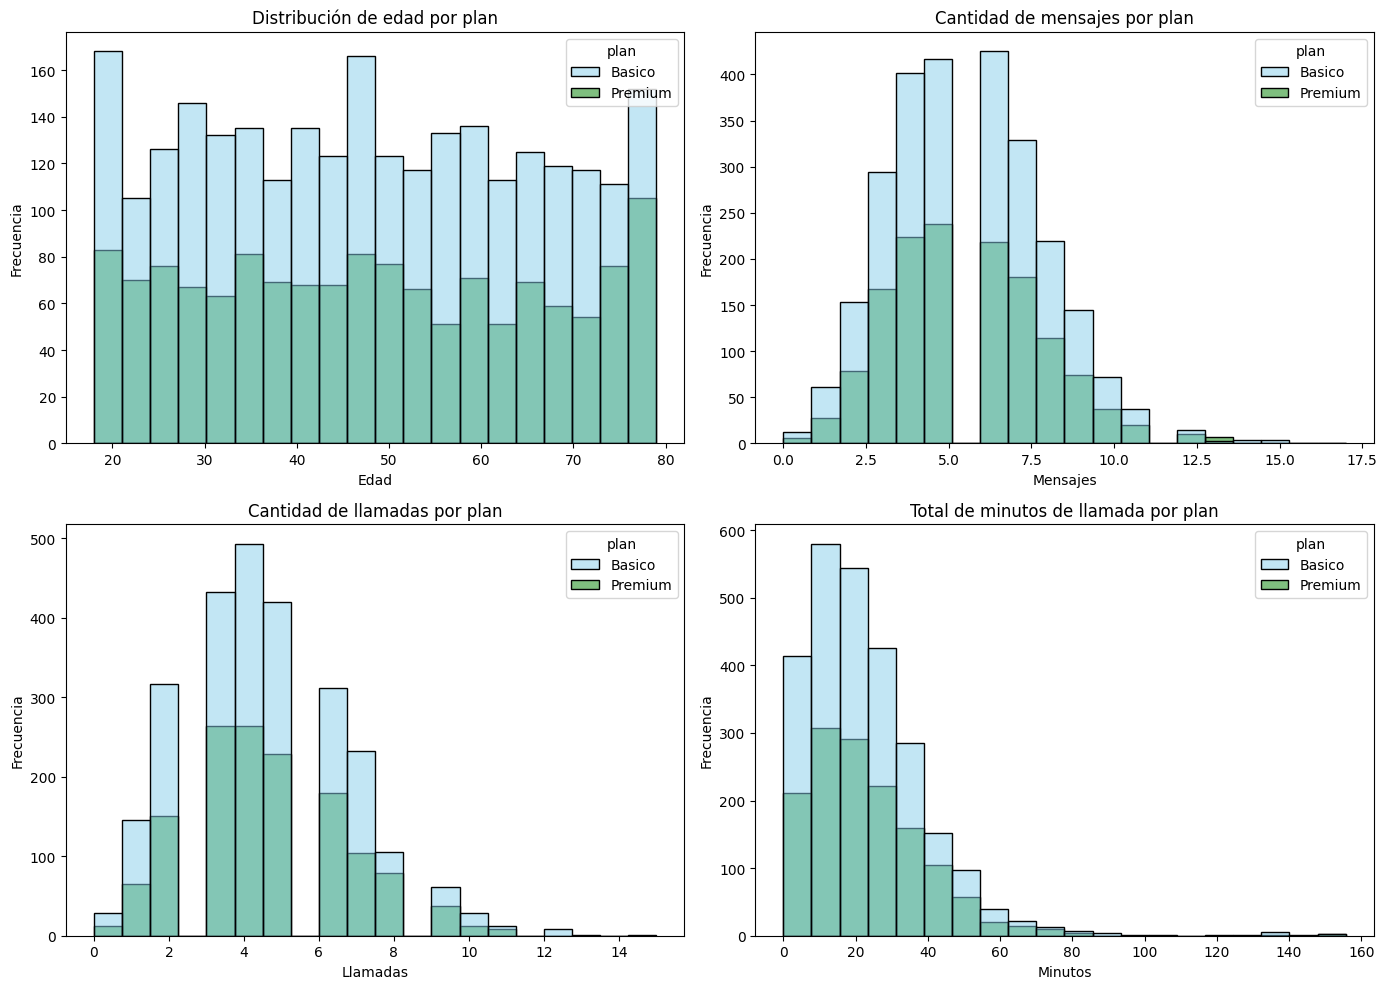

In [180]:
# Histograma para visualizar la edad (age)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
paleta = ['skyblue', 'green']
sns.histplot(data=users, x='age', hue='plan', palette=paleta, bins=20, ax=axes[0, 0])
axes[0, 0].set_title('Distribución de edad por plan')
axes[0, 0].set_xlabel('Edad')
axes[0, 0].set_ylabel('Frecuencia')

sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=paleta, bins=20, ax=axes[0, 1])
axes[0, 1].set_title('Cantidad de mensajes por plan')
axes[0, 1].set_xlabel('Mensajes')
axes[0, 1].set_ylabel('Frecuencia')

sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=paleta, bins=20, ax=axes[1, 0])
axes[1, 0].set_title('Cantidad de llamadas por plan')
axes[1, 0].set_xlabel('Llamadas')
axes[1, 0].set_ylabel('Frecuencia')

sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=paleta, bins=20, ax=axes[1, 1])
axes[1, 1].set_title('Total de minutos de llamada por plan')
axes[1, 1].set_xlabel('Minutos')
axes[1, 1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

💡Insights: 
- Distribución
- age (edad de los usuarios) 'dentro del plan premium la edad se ve sesgada a la derecha, hay una mayor cantidad de gente mayor usando el plan premium',  'el tipo de distribucion es simetrica obvio'
cant_mensajes 'dentro del plan premium la gente suele mandar mas mensajes, eso se debe a que la mayoria de gente cuenta mas con
un plan basico que uno premium'
cant_llamadas 'la mayoria de gente del plan basico suele hacer mas llamadas, pero en el plan premium hay mas gente que hace mas de 12 llamdas'
total_minutos_llamada 'aqui se ve una cantidad alta de gente que hace llamdas mas largas con el plan premium'



### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

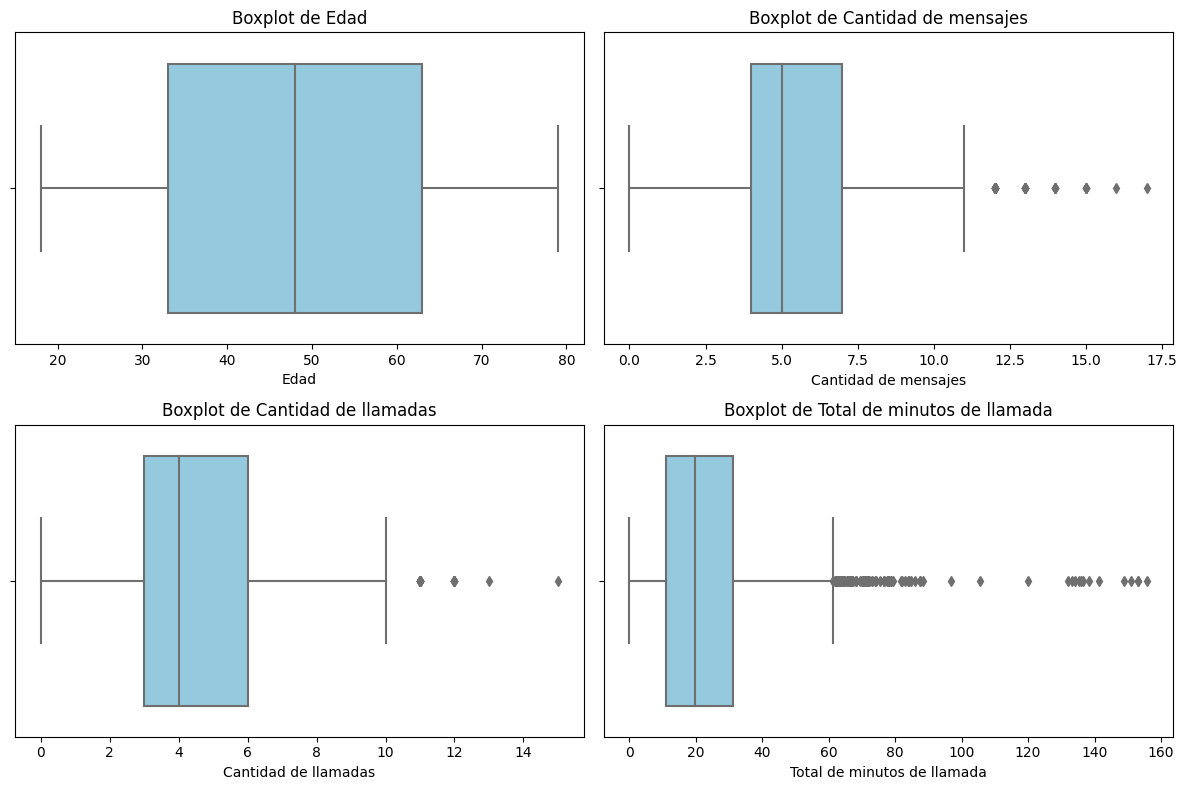

In [181]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
titulos = ['Edad', 'Cantidad de mensajes', 'Cantidad de llamadas', 'Total de minutos de llamada']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))\

for ax, col, titulo in zip(axes.flatten(), columnas_numericas, titulos):
    sns.boxplot(data=user_profile, x=col, color='skyblue', ax=ax)
    ax.set_title(f'Boxplot de {titulo}')
    ax.set_xlabel(titulo)

plt.tight_layout()
plt.show()


💡Insights: 
- Age: ...(no presente outliners)
- cant_mensajes: presenta muy pocos,sesgados  a la derecha pero no son tantos 
- cant_llamadas: presenta muy pocos a la derecha
- cant_minutos_llamada: esta es la que tiene mas cantidad de outliners, demasiados a la derecha 

In [182]:
# Calcular límites con el método IQR

for col in columnas_numericas:
    q1, q3 = user_profile[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = user_profile[(user_profile[col] < q1 - 1.5 * iqr) | (user_profile[col] > q3 + 1.5 * iqr)]
    print(f'{col}: {len(outliers)} outliers')



age: 0 outliers
cant_mensajes: 46 outliers
cant_llamadas: 30 outliers
cant_minutos_llamada: 96 outliers


In [183]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,22.836934
std,17.691541,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
Edad

Va de 18 a 79 años, con media (48.1) y mediana (48) casi idénticas. Eso indica una distribución simétrica, probablemente bastante uniforme.
No quedan valores raros: el mínimo de 18 y el máximo de 79 son plausibles, así que la limpieza del -999 funcionó.

Mensajes y llamadas

La media y la mediana están muy cerca (5.5 vs 5 mensajes, 4.5 vs 4 llamadas), con ligero sesgo a la derecha.
Hay usuarios con 0 mensajes o 0 llamadas, lo cual es normal.
Los máximos (17 mensajes, 15 llamadas) son varias veces la mediana, y de ahí salen los outliers que detectaste.

Minutos de llamada

Aquí el sesgo es más claro: la media (22.8) supera a la mediana (19.7), y el máximo (155.7) es unas 8 veces la mediana. Es la cola larga típica de telecomunicaciones.
Un usuario con 155 minutos totales no es imposible, así que se puede conservar.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [184]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
etiquetas = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, etiquetas, default='Alto uso')

# Verificar
print(user_profile['grupo_uso'].value_counts())

Uso medio    2943
Bajo uso      778
Alto uso      278
Name: grupo_uso, dtype: int64


In [185]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [186]:
# Crear columna grupo_edad
condiciones = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
etiquetas = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones, etiquetas, default='Adulto Mayor')
print(user_profile['grupo_edad'].value_counts())

Adulto          2017
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [187]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

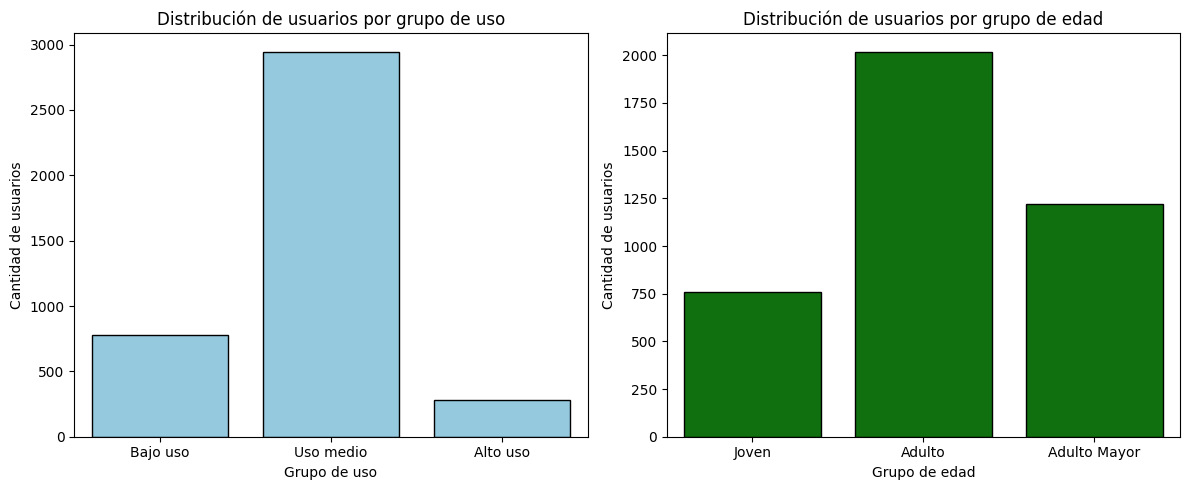

In [188]:
# Visualización de los segmentos por uso
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Grupo de uso
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'],
              color='skyblue', edgecolor='black', ax=axes[0])
axes[0].set_title('Distribución de usuarios por grupo de uso')
axes[0].set_xlabel('Grupo de uso')
axes[0].set_ylabel('Cantidad de usuarios')

# Grupo de edad
sns.countplot(data=user_profile, x='grupo_edad',
              order=['Joven', 'Adulto', 'Adulto Mayor'],
              color='green', edgecolor='black', ax=axes[1])
axes[1].set_title('Distribución de usuarios por grupo de edad')
axes[1].set_xlabel('Grupo de edad')
axes[1].set_ylabel('Cantidad de usuarios')

plt.tight_layout()
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Se detectaron tres problemas de calidad en la tabla users:

Edad (age): 55 registros (1.4%) tenían el valor -999, un código centinela de dato faltante. Se reemplazaron por la mediana calculada solo con edades válidas, para que el centinela no distorsionara el cálculo.
Fecha de registro (reg_date): 40 registros (1.0%) tenían fechas del año 2026, inconsistentes con el periodo de análisis. Se convirtieron a nulo (NaT).
Ciudad (city): 469 registros (11.7%) tenían valores nulos. Se dejaron como NaN, ya que la variable no interviene en la segmentación por edad y uso.

En la tabla usage, 22,076 de 40,000 registros (55.2%) tienen duration nulo. No es un error de captura: corresponde a los mensajes de texto, que por naturaleza no tienen duración. Por eso no requirió limpieza, y al construir la tabla agregada solo se sumaron los minutos de las llamadas.


🔍 **Segmentos por Edad**
- Se segmentó a los 3,999 usuarios por edad y por nivel de uso.

Por edad: Adultos de 30 a 59 años (2,017 usuarios, 50.4%), Adultos Mayores de 60 o más (1,222, 30.6%) y Jóvenes de 18 a 29 (760, 19.0%).
Por uso: la gran mayoría está en Uso medio (73.6%), seguido de Bajo uso (19.5%) y Alto uso (7.0%).
Cruce edad y uso: la distribución de uso es muy parecida en los tres grupos de edad. El Uso medio ronda el 73% en todos. Los Adultos tienen algo más de Alto uso (7.6%) y los Adultos Mayores algo más de Bajo uso (21.0% frente a 18.0% en Adultos). Con diferencias de pocos puntos porcentuales, la edad no parece ser un factor determinante del consumo en esta base


📊 **Segmentos por Nivel de Uso**
- Alto uso (7.0%): es el más valioso por consumo, porque genera más llamadas, mensajes y minutos, y por tanto más tráfico e ingreso potencial. También es el que más carga pone en la red. Se reparte de forma casi pareja entre edades, así que no es un nicho de un grupo etario.
Uso medio (73.6%): por tamaño es el más importante para el negocio. Aunque cada usuario consuma de forma moderada, es casi tres cuartas partes de la base, así que retenerlo es lo que más protege los ingresos totales.
Plan Premium: Básico y Premium se comportan prácticamente igual. Ambos promedian 5.5 mensajes y 4.5 llamadas, con 22.6 minutos en Básico y 23.3 en Premium. El Alto uso es incluso un poco mayor en Básico (7.1% frente a 6.6%). Por tanto, el consumo de voz y mensajes no justifica por sí mismo la diferencia entre planes.


➡️ Esto sugiere que Se detectaron 46 usuarios atípicos en mensajes (1.2%), 30 en llamadas (0.8%) y 96 en minutos de llamada (2.4%). En edad no hubo ninguno. El máximo de minutos (155.7) es unas ocho veces la mediana (19.7). Se conservaron porque son comportamientos plausibles de usuarios intensivos, no errores de captura.

Implican que una minoría pequeña concentra un consumo muy superior al típico. Son clientes de alto valor, pero también un riesgo: si su plan no se ajusta a su consumo, pueden generar pérdida de margen o migrar a la competencia. Los outliers en minutos son los más numerosos, así que la voz es donde más se separan los usuarios intensivos.


💡 **Recomendaciones**
- Revisar la propuesta de valor del plan Premium. Si sus usuarios consumen lo mismo que los de Básico, el plan debe diferenciarse por otros beneficios (datos, velocidad, servicios adicionales, atención prioritaria) o reajustar su precio. Si no, los clientes pueden percibir que pagan de más.
Crear un plan para usuarios intensivos, con más minutos o llamadas ilimitadas, dirigido a los outliers y al 7% de Alto uso. Es una oportunidad de upselling, sobre todo entre quienes hoy están en Básico.
Plan de entrada para Bajo uso (19.5%): una opción más económica o de pago por uso, para reducir el riesgo de abandono de clientes que pagan más de lo que consumen.
Enfocar la retención en Uso medio, por ser el 73.6% de la base: promociones de lealtad y beneficios por permanencia.
No segmentar las ofertas solo por edad, ya que los grupos se comportan de forma similar. Es mejor segmentar por nivel de uso.
Monitorear el consumo extremo: alertas para ofrecer proactivamente un plan superior a quien excede de forma sostenida su consumo habitual.
Calidad de datos: validar en origen la edad y la fecha de registro para evitar centinelas como -999 y fechas inconsistentes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`